In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    else:
        print('Double check observable!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n_array = []
    wtot_array = []
    for i in range(0, len(w_array)):
        n_array.append( df[df.w == w_array[i]].shape[0] )
        wtot_array.append( sum(df[df.w == w_array[i]]['w']) )
    n = 0
    for i in range(0, len(w_array)):
        if (wtot_array[i] != 0):
            n += wtot_array[i]*n_array[i]/sum(wtot_array)
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err

In [5]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [6]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = '15'

In [7]:
observables1 = ['pt','b','dr','z','epair','pt1','pt2','reject','w']
observabless1 = ['pts','bs','drs','zs','epairs','pt1s','pt2s','rejects','ws']

In [8]:
df_pythia= applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0613_chargedrc.root', "MatchedTree"),'b!=0 and b!=-9 and pt>5 and reject<=0 and rejects<=0')

In [9]:
df_pythia.shape[0]

349521

In [10]:
w_array = np.unique(df_pythia['w'])

In [11]:
df_pythia_array = [ df_pythia[(df_pythia.pt>20) & (df_pythia.pt<25)],\
                    df_pythia[(df_pythia.pt>25) & (df_pythia.pt<30)],\
                    df_pythia[(df_pythia.pt>30) & (df_pythia.pt<40)] ]

In [12]:
rc_pythia_array = []
rc_err_pythia_array = []
for i in range(0, len(df_pythia_array)):
    rc_pythia_array.append(getRcAndErr(df_pythia_array[i], 'b')[0])
    rc_err_pythia_array.append(getRcAndErr(df_pythia_array[i], 'b')[1])

In [13]:
rc_pythia_array

[-0.38826026009188924, -0.39369460615230406, -0.3768098484983996]

In [14]:
rc_err_pythia_array

[0.009936039809013149, 0.009560870977200512, 0.012652147517818062]

In [14]:
df0 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_50pthat_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df1 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_45pthat50_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df2 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_40pthat45_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df3 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_35pthat40_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df4 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_30pthat35_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df5 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_25pthat30_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df6 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_20pthat25_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df7 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_15pthat20_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df8 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_11pthat15_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df9 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_10pthat11_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)

In [15]:
w0=(float)(df0.iloc[df0.shape[0]-1]['xsec'])/200000
w1=(float)(df1.iloc[df1.shape[0]-1]['xsec'])/200000
w2=(float)(df2.iloc[df2.shape[0]-1]['xsec'])/200000
w3=(float)(df3.iloc[df3.shape[0]-1]['xsec'])/200000
w4=(float)(df4.iloc[df4.shape[0]-1]['xsec'])/200000
w5=(float)(df5.iloc[df5.shape[0]-1]['xsec'])/200000
w6=(float)(df6.iloc[df6.shape[0]-1]['xsec'])/200000
w7=(float)(df7.iloc[df7.shape[0]-1]['xsec'])/200000
w8=(float)(df8.iloc[df8.shape[0]-1]['xsec'])/200000
w9=(float)(df9.iloc[df9.shape[0]-1]['xsec'])/200000
df0['w']=np.ones(df0.shape[0])*w0
df1['w']=np.ones(df1.shape[0])*w1
df2['w']=np.ones(df2.shape[0])*w2
df3['w']=np.ones(df3.shape[0])*w3
df4['w']=np.ones(df4.shape[0])*w4
df5['w']=np.ones(df5.shape[0])*w5
df6['w']=np.ones(df6.shape[0])*w6
df7['w']=np.ones(df7.shape[0])*w7
df8['w']=np.ones(df8.shape[0])*w8
df9['w']=np.ones(df9.shape[0])*w9
df = pd.concat([df0,df1,df2,df3,df4,df5,df6,df7,df8,df9])
df_herwig = df[['pt','b_ch','w']]
df_herwig = applyCut(df_herwig, 'b_ch!=0 and b_ch!=-9 and pt>5')

In [16]:
df_herwig.shape[0]

2805846

In [17]:
w_array = np.unique(df_herwig['w'])

In [18]:
df_herwig_array = [ df_herwig[(df_herwig.pt>20) & (df_herwig.pt<25)],\
                    df_herwig[(df_herwig.pt>25) & (df_herwig.pt<30)],\
                    df_herwig[(df_herwig.pt>30) & (df_herwig.pt<40)] ]

In [19]:
rc_herwig_array = []
rc_err_herwig_array = []
for i in range(0, len(df_herwig_array)):
    rc_herwig_array.append(getRcAndErr(df_herwig_array[i], 'b_ch')[0])
    rc_err_herwig_array.append(getRcAndErr(df_herwig_array[i], 'b_ch')[1])

In [20]:
rc_herwig_array

[-0.35014446350294776, -0.352569479065421, -0.34965492934444825]

In [21]:
rc_err_herwig_array

[0.005106074602778532, 0.004791818288603352, 0.003555904722480963]

In [22]:
df0 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_50pthat_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df1 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_45pthat50_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df2 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_40pthat45_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df3 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_35pthat40_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df4 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_30pthat35_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df5 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_25pthat30_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df6 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_20pthat25_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df7 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_15pthat20_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df8 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_11pthat15_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)

In [23]:
w0=(float)(df0.iloc[df0.shape[0]-1]['xsec'])/200000
w1=(float)(df1.iloc[df1.shape[0]-1]['xsec'])/200000
w2=(float)(df2.iloc[df2.shape[0]-1]['xsec'])/200000
w3=(float)(df3.iloc[df3.shape[0]-1]['xsec'])/200000
w4=(float)(df4.iloc[df4.shape[0]-1]['xsec'])/200000
w5=(float)(df5.iloc[df5.shape[0]-1]['xsec'])/200000
w6=(float)(df6.iloc[df6.shape[0]-1]['xsec'])/200000
w7=(float)(df7.iloc[df7.shape[0]-1]['xsec'])/200000
w8=(float)(df8.iloc[df8.shape[0]-1]['xsec'])/200000
df0['w']=np.ones(df0.shape[0])*w0
df1['w']=np.ones(df1.shape[0])*w1
df2['w']=np.ones(df2.shape[0])*w2
df3['w']=np.ones(df3.shape[0])*w3
df4['w']=np.ones(df4.shape[0])*w4
df5['w']=np.ones(df5.shape[0])*w5
df6['w']=np.ones(df6.shape[0])*w6
df7['w']=np.ones(df7.shape[0])*w7
df8['w']=np.ones(df8.shape[0])*w8
df = pd.concat([df0,df1,df2,df3,df4,df5,df6,df7,df8])
df_pythia8 = df[['pt','b_ch','w']]
df_pythia8 = applyCut(df_pythia8, 'b_ch!=0 and b_ch!=-9 and pt>5')

In [24]:
df_pythia8.shape[0]

2498571

In [25]:
w_array = np.unique(df_pythia8['w'])

In [26]:
df_pythia8_array = [ df_pythia8[(df_pythia8.pt>20) & (df_pythia8.pt<25)],\
                    df_pythia8[(df_pythia8.pt>25) & (df_pythia8.pt<30)],\
                    df_pythia8[(df_pythia8.pt>30) & (df_pythia8.pt<40)] ]

In [27]:
rc_pythia8_array = []
rc_err_pythia8_array = []
for i in range(0, len(df_pythia8_array)):
    rc_pythia8_array.append(getRcAndErr(df_pythia8_array[i], 'b_ch')[0])
    rc_err_pythia8_array.append(getRcAndErr(df_pythia8_array[i], 'b_ch')[1])

In [28]:
rc_pythia8_array

[-0.36833811382365794, -0.35768591344782313, -0.37211991693435187]

In [29]:
rc_err_pythia8_array

[0.004562456189078292, 0.00423700272438436, 0.003130412728388453]

In [39]:
np.sqrt(rc_err_corrected_array**2+rc_err_det_array**2)+0.03

array([0.03991036, 0.04462855, 0.04255749])

In [36]:
rc_corrected_array = np.array([-0.3389452430645336, -0.34607953567344624, -0.3263463116487207])
rc_err_corrected_array = np.array([0.003328304308617994, 0.006772192457235017, 0.012550873791080731])
rc_err_det_array = np.array([0.009334756803589306, -0.012966564790529267, 0.00040748331744022703])
#rc_err

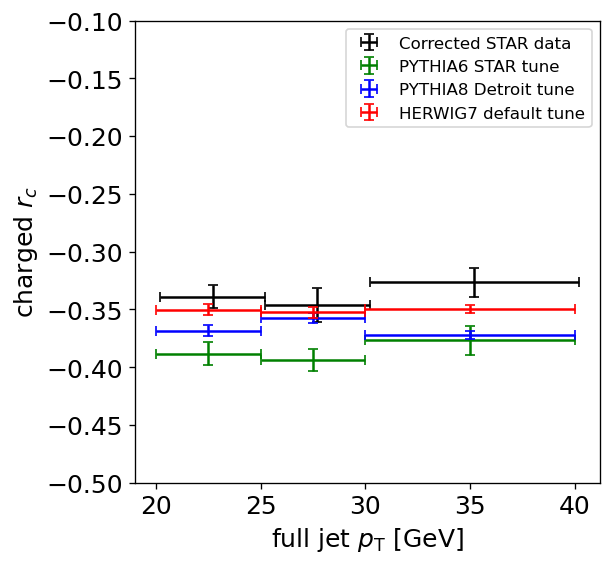

In [43]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.7, 27.7, 35.2], rc_corrected_array, xerr=[2.5, 2.5, 5], yerr=np.sqrt(rc_err_corrected_array**2+rc_err_det_array**2), capsize=3, color='k', ls='none', label='Corrected STAR data')
plt.errorbar([22.5, 27.5, 35], rc_pythia_array, xerr=[2.5, 2.5, 5], yerr=rc_err_pythia_array, capsize=3, color='g', ls='none', label='PYTHIA6 STAR tune')
plt.errorbar([22.5, 27.5, 35], rc_pythia8_array, xerr=[2.5, 2.5, 5], yerr=rc_err_pythia8_array, capsize=3, color='b', ls='none', label='PYTHIA8 Detroit tune')
plt.errorbar([22.5, 27.5, 35], rc_herwig_array, xerr=[2.5, 2.5, 5], yerr=rc_err_herwig_array, capsize=3, color='r', ls='none', label='HERWIG7 default tune')
#eb2[-1][0].set_linestyle('dotted')
#eb2[-1][1].set_linestyle('dotted')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.5,-0.1)
plt.legend(fontsize=10)

In [16]:
w_array = np.unique(df_pythia['w'])

In [14]:
df_pythia_array = [ df_pythia[(df_pythia.pt>15) & (df_pythia.pt<17.5)],\
                    df_pythia[(df_pythia.pt>17.5) & (df_pythia.pt<20)],\
                    df_pythia[(df_pythia.pt>20) & (df_pythia.pt<22.5)],\
                    df_pythia[(df_pythia.pt>22.5) & (df_pythia.pt<25)],\
                    df_pythia[(df_pythia.pt>25) & (df_pythia.pt<27.5)],\
                    df_pythia[(df_pythia.pt>27.5) & (df_pythia.pt<30)],\
                    df_pythia[(df_pythia.pt>30) & (df_pythia.pt<32.5)],\
                    df_pythia[(df_pythia.pt>32.5) & (df_pythia.pt<35)],\
                    df_pythia[(df_pythia.pt>35) & (df_pythia.pt<37.5)],\
                    df_pythia[(df_pythia.pt>37.5) & (df_pythia.pt<40)]]

In [17]:
rc_pythia_array = []
rc_err_pythia_array = []
for i in range(0, len(df_pythia_array)):
    rc_pythia_array.append(getRcAndErr(df_pythia_array[i], 'b')[0])
    rc_err_pythia_array.append(getRcAndErr(df_pythia_array[i], 'b')[1])

In [18]:
w_array = np.unique(df_herwig['w'])

In [19]:
df_herwig_array = [ df_herwig[(df_herwig.pt>15) & (df_herwig.pt<17.5)],\
                    df_herwig[(df_herwig.pt>17.5) & (df_herwig.pt<20)],\
                    df_herwig[(df_herwig.pt>20) & (df_herwig.pt<22.5)],\
                    df_herwig[(df_herwig.pt>22.5) & (df_herwig.pt<25)],\
                    df_herwig[(df_herwig.pt>25) & (df_herwig.pt<27.5)],\
                    df_herwig[(df_herwig.pt>27.5) & (df_herwig.pt<30)],\
                    df_herwig[(df_herwig.pt>30) & (df_herwig.pt<32.5)],\
                    df_herwig[(df_herwig.pt>32.5) & (df_herwig.pt<35)],\
                    df_herwig[(df_herwig.pt>35) & (df_herwig.pt<37.5)],\
                    df_herwig[(df_herwig.pt>37.5) & (df_herwig.pt<40)]]

In [20]:
rc_herwig_array = []
rc_err_herwig_array = []
for i in range(0, len(df_herwig_array)):
    rc_herwig_array.append(getRcAndErr(df_herwig_array[i], 'b_ch')[0])
    rc_err_herwig_array.append(getRcAndErr(df_herwig_array[i], 'b_ch')[1])

In [21]:
w_array = np.unique(df_pythia8['w'])

In [22]:
df_pythia8_array = [ df_pythia8[(df_pythia8.pt>15) & (df_pythia8.pt<17.5)],\
                    df_pythia8[(df_pythia8.pt>17.5) & (df_pythia8.pt<20)],\
                    df_pythia8[(df_pythia8.pt>20) & (df_pythia8.pt<22.5)],\
                    df_pythia8[(df_pythia8.pt>22.5) & (df_pythia8.pt<25)],\
                    df_pythia8[(df_pythia8.pt>25) & (df_pythia8.pt<27.5)],\
                    df_pythia8[(df_pythia8.pt>27.5) & (df_pythia8.pt<30)],\
                    df_pythia8[(df_pythia8.pt>30) & (df_pythia8.pt<32.5)],\
                    df_pythia8[(df_pythia8.pt>32.5) & (df_pythia8.pt<35)],\
                    df_pythia8[(df_pythia8.pt>35) & (df_pythia8.pt<37.5)],\
                    df_pythia8[(df_pythia8.pt>37.5) & (df_pythia8.pt<40)]]

In [23]:
rc_pythia8_array = []
rc_err_pythia8_array = []
for i in range(0, len(df_pythia8_array)):
    rc_pythia8_array.append(getRcAndErr(df_pythia8_array[i], 'b_ch')[0])
    rc_err_pythia8_array.append(getRcAndErr(df_pythia8_array[i], 'b_ch')[1])

In [34]:
len(rc_pythia_array)

10

In [35]:
x = np.arange(16.25, 41.25, 2.5)
xerr = np.ones(len(x))*1.25

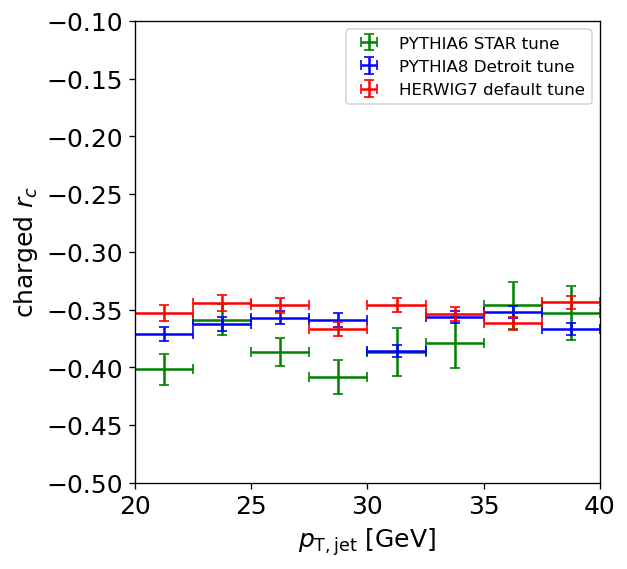

In [37]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(x, rc_pythia_array, xerr=1.25, yerr=rc_err_pythia_array, capsize=3, color='g', ls='none', label='PYTHIA6 STAR tune')
plt.errorbar(x, rc_pythia8_array, xerr=1.25, yerr=rc_err_pythia8_array, capsize=3, color='b', ls='none', label='PYTHIA8 Detroit tune')
plt.errorbar(x, rc_herwig_array, xerr=1.25, yerr=rc_err_herwig_array, capsize=3, color='r', ls='none', label='HERWIG7 default tune')
plt.xlabel('$p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.5,-0.1)
plt.xlim(20,40)
plt.legend(fontsize=10)